# 00-3　觀看前須知：讀懂 03 狹義相對論需要的觀念

**給誰看**：讀過 [00-1](01_before_newton.ipynb)、物理學到高中程度的人。
**目標**：讀完再去看 [03 狹義相對論](../03_special_relativity/01_special_relativity.ipynb)。

狹義相對論的數學其實**只用到畢氏定理和平方根**，難的是觀念：它要你放棄「時間對所有人都一樣」這個從小就相信的事。
這本先把需要的工具和「衝突」準備好。

| 章節 | 內容 | 03 對應的地方 |
|---|---|---|
| 0 | 符號對照表 | 全部 |
| 1 | 參考系與相對速度 | 「從火車上看」「從月台上看」 |
| 2 | 光速不變：一個看起來不可能的事實 | 整個 03 的出發點 |
| 3 | 光秒、光年：用光當尺 | $c = 1$ 的單位 |
| 4 | 畢氏定理和光鐘 | 實驗 1 推導時間變慢 |
| 5 | 平方根近似：為什麼日常感覺不到 | $\gamma \approx 1 + v^2/2c^2$ |
| 6 | 時空圖：把時間畫成一個方向 | 實驗 3、4 的圖 |
| 7 | 衛星的速度和高度 | 實驗 6 的 GPS |
| 8 | 很短的時間：微秒、奈秒 | 緲子、GPS 的誤差 |

## 0. 符號對照表

| 符號 | 念法 | 意思 |
|---|---|---|
| $c$ | | 光速，約 $3\times10^8$ m/s（每秒 30 萬公里） |
| $v$ | | 物體（或參考系）的速度 |
| $\beta$ | beta | $v/c$，速度是光速的幾成，0 到 1 之間 |
| $\gamma$ | gamma | **勞倫茲因子** $1/\sqrt{1 - v^2/c^2}$，相對論效應的大小，永遠 ≥ 1 |
| $t$、$t'$ | t、t prime | 兩個不同觀察者各自量到的時間。加一撇代表「另一個參考系」 |
| $\Delta t$ | | 兩件事之間經過的時間 |
| $\tau$ | tau | **固有時**：跟著物體一起走的時鐘量到的時間 |
| $ct$ | | 時間乘上光速，單位變成長度，「光在這段時間裡走多遠」 |
| μs | 微秒 | $10^{-6}$ 秒，百萬分之一秒 |
| ns | 奈秒 | $10^{-9}$ 秒，十億分之一秒 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

c = 299_792_458.0   # 光速 (m/s)，這是定義值，完全精確

## 1. 參考系與相對速度

**白話**：「速度」一定是**相對於某個東西**。你坐在時速 100 公里的火車上：

- 相對於火車，你的速度是 0
- 相對於月台，你的速度是 100 km/h

用來量位置和時間的那個「基準」，叫**參考系**。

**伽利略相對性**（牛頓力學）：在火車上往前丟一顆球，球相對火車 20 km/h，那相對月台就是

$$u = 100 + 20 = 120 \text{ km/h}$$

速度**直接相加**，這叫**伽利略速度加法**，非常直覺。

另一個重點：**等速前進的火車裡，所有物理實驗的結果都和靜止時一樣**。窗簾拉上，你分不出火車是停著，還是在平穩地等速前進。
這叫**相對性原理**，伽利略在 1632 年就提出了。

In [2]:
train = 100        # 火車相對月台 (km/h)
ball = 20          # 球相對火車 (km/h)
print(f"伽利略：球相對月台 = {train} + {ball} = {train + ball} km/h")
print(f"如果往後丟：      = {train} + ({-ball}) = {train - ball} km/h")

伽利略：球相對月台 = 100 + 20 = 120 km/h
如果往後丟：      = 100 + (-20) = 80 km/h


## 2. 光速不變：一個看起來不可能的事實

如果把球換成**光**呢？在火車上開手電筒往前照，照伽利略的算法，月台上的人應該量到光速是 $c + v$。

**但實驗說不是。** 不管光源怎麼動、觀察者怎麼動，**每個人量到的光速都剛好是 $c$**。

- **1887 年邁克生–莫立實驗**：地球繞太陽的速度約 30 km/s，方向一年四季在變。如果光速會和地球速度相加，不同方向的光速應該不一樣。他們用極精密的干涉儀去量，**完全量不到差別**。
- 之後一百多年，各種實驗都確認了這一點，精確度已經到 $10^{-17}$ 以上。

**衝突**：

| | 伽利略加法 | 實驗 |
|---|---|---|
| 火車上的球 | 100 + 20 = 120 ✓ | 120 ✓（差異小到量不出來） |
| 火車上的光 | $c + v$ | **$c$**，不多不少 |

1905 年愛因斯坦的做法是：**兩個都當成真的**。

1. 相對性原理：等速運動的參考系裡，物理定律都一樣
2. 光速不變：所有參考系量到的光速都是 $c$

要讓兩件事同時成立，唯一的辦法是：**時間和長度本身，在不同參考系裡不一樣**。這就是 03 要做的事。

## 3. 光秒、光年：用光當尺

光速是宇宙的速度上限，又對每個人都一樣，所以很適合拿來當單位：

- **1 光秒**：光在 1 秒內走的距離，約 30 萬公里
- **1 光年**：光在 1 年內走的距離，約 9.46 兆公里

用「光秒」量距離、「秒」量時間時，**光速剛好等於 1**。物理學家常用這種 $c = 1$ 的單位，就像 00-1 讓 $GM = 4\pi^2$、02 讓 $\hbar = 1$。

In [3]:
places = [
    ("地球一圈", 40_075e3),
    ("GPS 衛星的高度", 20_200e3),
    ("地球到月球", 384_400e3),
    ("地球到太陽", 1.496e11),
    ("地球到最近的恆星（比鄰星）", 4.017e16),
]
for name, d in places:
    t = d / c
    if t < 60:
        s = f"{t:.3f} 光秒"
    elif t < 3600 * 24 * 365:
        s = f"{t / 60:.1f} 光分"
    else:
        s = f"{t / (3600 * 24 * 365.25):.2f} 光年"
    print(f"{name:<16}{d / 1e3:>18,.0f} km  = {s}")

print(f"\n光在 1 奈秒 (ns) 內走 {c * 1e-9 * 100:.1f} 公分")

地球一圈                        40,075 km  = 0.134 光秒
GPS 衛星的高度                   20,200 km  = 0.067 光秒
地球到月球                      384,400 km  = 1.282 光秒
地球到太陽                  149,600,000 km  = 8.3 光分
地球到最近的恆星（比鄰星）   40,170,000,000,000 km  = 4.25 光年

光在 1 奈秒 (ns) 內走 30.0 公分


**記住最後一行**：光 1 奈秒只走 30 公分。所以 GPS 時鐘差 1 奈秒，定位就差 30 公分。第 8 章和 03 實驗 6 會用到。

## 4. 畢氏定理和光鐘

03 推導「時間變慢」只需要一個工具：**直角三角形的畢氏定理** $a^2 + b^2 = c^2$。

**光鐘**是一個想像中的時鐘：兩面鏡子上下相對，一道光在中間來回彈，彈一次算「滴答」一下。

- **火車上的人**看光鐘（光鐘也在火車上）：光直直地上下彈。
- **月台上的人**看：火車往前跑，所以光走的是**斜線**，形成一個三角形。

斜線比直線長，但光速對兩個人都是 $c$，所以月台上的人會看到：**光走斜線要花比較久的時間**。下面先把這個三角形畫出來：

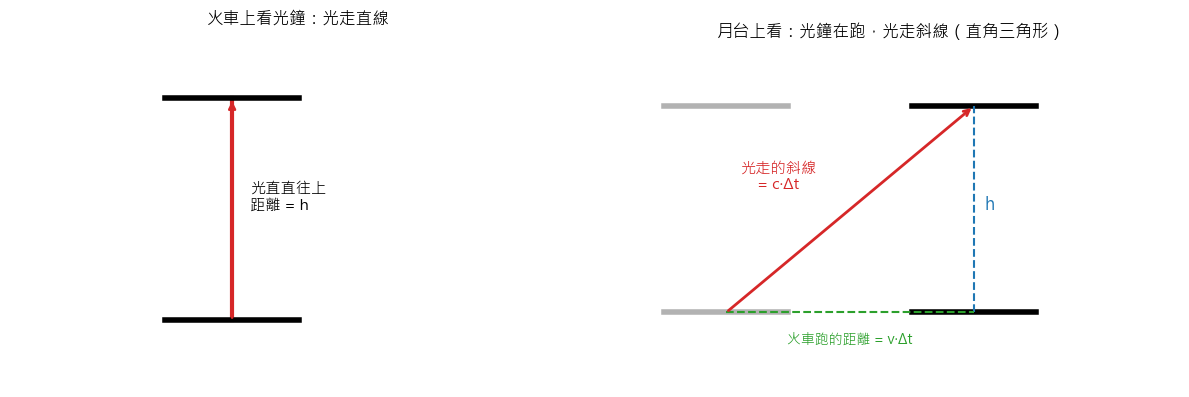

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
h = 1.0
ax = axes[0]
ax.plot([0, 0], [0, h], "C3", lw=3)
ax.annotate("", xy=(0, h), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C3", lw=2))
for y in (0, h):
    ax.plot([-0.3, 0.3], [y, y], "k", lw=4)
ax.text(0.08, h / 2, "光直直往上\n距離 = h", fontsize=11)
ax.set_xlim(-1, 1.6)
ax.set_ylim(-0.3, 1.3)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("火車上看光鐘：光走直線")

ax = axes[1]
D = 1.2
for x0 in (0, D):
    ax.plot([x0 - 0.3, x0 + 0.3], [0, 0], "k", lw=4, alpha=0.3 if x0 == 0 else 1)
    ax.plot([x0 - 0.3, x0 + 0.3], [h, h], "k", lw=4, alpha=0.3 if x0 == 0 else 1)
ax.annotate("", xy=(D, h), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C3", lw=2))
ax.plot([D, D], [0, h], "C0--")
ax.plot([0, D], [0, 0], "C2--")
ax.text(D + 0.05, h / 2, "h", color="C0", fontsize=12)
ax.text(D / 2, -0.15, "火車跑的距離 = v·Δt", color="C2", ha="center")
ax.text(D / 2 - 0.35, h / 2 + 0.1, "光走的斜線\n= c·Δt", color="C3", fontsize=11, ha="center")
ax.set_xlim(-0.6, 2.2)
ax.set_ylim(-0.3, 1.3)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("月台上看：光鐘在跑，光走斜線（直角三角形）")
plt.tight_layout()
plt.show()

右邊的直角三角形：斜邊是光走的距離 $c\,\Delta t$，底邊是火車跑的距離 $v\,\Delta t$，高是鏡子間距 $h$。
畢氏定理 $(c\Delta t)^2 = (v\Delta t)^2 + h^2$，03 實驗 1 會從這裡一步一步推出時間變慢的公式。

## 5. 平方根近似：為什麼日常感覺不到

03 會得到一個關鍵的數：**勞倫茲因子**

$$\gamma = \frac{1}{\sqrt{1 - v^2/c^2}}$$

移動中的時鐘會慢 $\gamma$ 倍。速度遠小於光速時，有一個很好用的近似：

$$\gamma \approx 1 + \frac{1}{2}\frac{v^2}{c^2}\qquad(v \ll c)$$

所以「慢了多少比例」大約是 $\frac{1}{2}(v/c)^2$。$v/c$ 本來就很小，**平方之後更小**。

In [5]:
things = [
    ("高鐵", 300 / 3.6),
    ("民航機", 900 / 3.6),
    ("子彈", 1000),
    ("國際太空站", 7660),
    ("GPS 衛星", 3874),
    ("地球繞太陽", 29_780),
    ("宇宙射線緲子", 0.998 * c),
]
print(f"{'物體':<12}{'速度 (m/s)':>14}{'v/c':>12}{'γ − 1（精確）':>16}{'v²/2c²（近似）':>16}")
for name, v in things:
    b = v / c
    exact = np.expm1(-0.5 * np.log1p(-b**2))   # = 1/√(1−β²) − 1，用這種寫法避免小數相減的浮點誤差
    print(f"{name:<12}{v:>14.4g}{b:>12.2e}{exact:>16.3e}{b**2 / 2:>16.3e}")

物體                速度 (m/s)         v/c       γ − 1（精確）      v²/2c²（近似）
高鐵                   83.33    2.78e-07       3.863e-14       3.863e-14
民航機                    250    8.34e-07       3.477e-13       3.477e-13
子彈                    1000    3.34e-06       5.563e-12       5.563e-12
國際太空站                 7660    2.56e-05       3.264e-10       3.264e-10
GPS 衛星                3874    1.29e-05       8.349e-11       8.349e-11
地球繞太陽            2.978e+04    9.93e-05       4.934e-09       4.934e-09
宇宙射線緲子           2.992e+08    9.98e-01       1.482e+01       4.980e-01


**觀察**：

- 日常最快的東西（子彈、飛機），$\gamma - 1$ 也只有 $10^{-12}$ 等級。子彈就算一整天都在飛，時鐘也只慢不到 1 奈秒。所以伽利略和牛頓用了兩三百年都沒發現問題。
- 近似公式在 $v \ll c$ 時和精確值一模一樣（多出來的誤差小到印不出來）。
- 只有接近光速的緲子，$\gamma$ 才變得很大（約 16）。這時近似公式**完全失效**（算出 0.5，實際是 14.8），一定要用精確公式。

**這和 01、02 的結論同一個模式**：02 是 $\hbar \to 0$ 回到牛頓，這裡是 $v/c \to 0$（等同 $c \to \infty$）回到牛頓。

## 6. 時空圖：把時間畫成一個方向

把**空間**畫在橫軸、**時間**畫在縱軸。時間乘上 $c$（變成 $ct$），兩個軸的單位就一樣，都是長度。

一個物體在時空圖上畫出的線，叫**世界線**：

- **靜止的物體**：位置不變，時間一直往上走，所以是**垂直線**
- **等速移動的物體**：斜線，越快越斜
- **光**：剛好是 **45°** 的斜線（每 1 單位時間走 1 單位距離）
- 沒有東西能比光快，所以任何物體的世界線都**比 45° 陡**

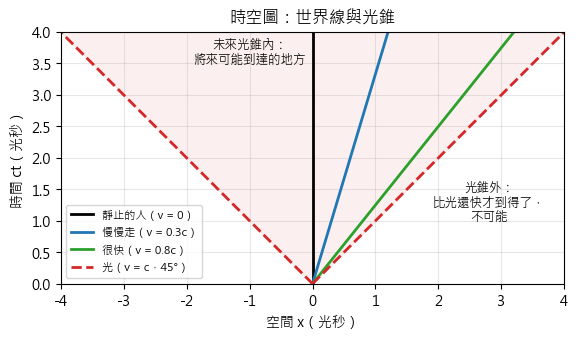

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ct = np.linspace(0, 4, 10)
ax.plot(np.zeros_like(ct), ct, "k", lw=2, label="靜止的人（v = 0）")
ax.plot(0.3 * ct, ct, "C0", lw=2, label="慢慢走（v = 0.3c）")
ax.plot(0.8 * ct, ct, "C2", lw=2, label="很快（v = 0.8c）")
ax.plot(ct, ct, "C3--", lw=2, label="光（v = c，45°）")
ax.plot(-ct, ct, "C3--", lw=2)
ax.fill_between(np.linspace(-4, 4, 100), np.abs(np.linspace(-4, 4, 100)), 4, color="C3", alpha=0.07)
ax.text(-1.0, 3.5, "未來光錐內：\n將來可能到達的地方", ha="center", fontsize=9)
ax.text(2.8, 1.0, "光錐外：\n比光還快才到得了，\n不可能", ha="center", fontsize=9)
ax.set_xlim(-4, 4)
ax.set_ylim(0, 4)
ax.set_aspect("equal")
ax.set_xlabel("空間 x（光秒）")
ax.set_ylabel("時間 ct（光秒）")
ax.set_title("時空圖：世界線與光錐")
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.3)
plt.show()

**光錐**：從一個事件出發，光往兩邊 45° 射出，形成一個 V 字形（在三維空間裡是圓錐）。
只有光錐**裡面**的事件，才可能被這個事件影響。這是相對論的**因果結構**，04 單元的黑洞就是「光錐倒向內部、誰都出不來」的地方。

## 7. 衛星的速度和高度

03 實驗 6 要算 GPS 衛星上的時鐘。需要衛星的速度，可以用 00-1 第 4 章的「引力提供向心力」來算：

$$\frac{v^2}{r} = \frac{GM}{r^2}\quad\Rightarrow\quad v = \sqrt{\frac{GM}{r}}$$

$r$ 是衛星到**地球中心**的距離（地球半徑加上高度）。

In [7]:
GM_earth = 3.986004418e14       # 地球的 GM (m³/s²)
R_earth = 6.371e6               # 地球平均半徑 (m)

for name, r in [("國際太空站（高 420 km）", R_earth + 420e3),
                ("GPS 衛星（軌道半徑 26,560 km）", 26_560e3),
                ("地球同步衛星（軌道半徑 42,164 km）", 42_164e3)]:
    v = np.sqrt(GM_earth / r)
    T = 2 * np.pi * r / v
    print(f"{name:<28} 速度 {v / 1000:.2f} km/s，繞一圈 {T / 3600:.2f} 小時")

國際太空站（高 420 km）              速度 7.66 km/s，繞一圈 1.55 小時
GPS 衛星（軌道半徑 26,560 km）       速度 3.87 km/s，繞一圈 11.97 小時
地球同步衛星（軌道半徑 42,164 km）       速度 3.07 km/s，繞一圈 23.93 小時


GPS 衛星每 11.97 小時繞地球一圈，剛好是「半個恆星日」，這樣它每天會在同一時間經過天空的同一位置。
它的速度約 3.87 km/s，比子彈快好幾倍，但 $v/c$ 也才 $1.3\times10^{-5}$。

## 8. 很短的時間：微秒、奈秒

| 單位 | 秒 | 光在這段時間走多遠 | 例子 |
|---|---|---|---|
| 1 毫秒 (ms) | $10^{-3}$ | 300 km | 螢幕更新一幀約 16 ms |
| 1 微秒 (μs) | $10^{-6}$ | 300 m | 緲子的平均壽命約 2.2 μs |
| 1 奈秒 (ns) | $10^{-9}$ | 30 cm | 電腦 CPU 一個時脈約 0.3 ns |

GPS 的定位原理是「量訊號從衛星飛到你這裡花了多久」，再乘上光速得到距離。
所以衛星時鐘只要偏 1 μs，距離就差 300 公尺。相對論讓 GPS 時鐘每天偏 38 μs，**不修正的話，一天就會累積超過 10 公里的誤差**。03 和 04 會把這個數字算出來。

## 準備好了：去讀 03

| 你在 03 看到 | 這本的哪裡 |
|---|---|
| 參考系、「從火車上看」 | 第 1 章 |
| 光速不變、兩個假設 | 第 2 章 |
| $c = 1$ 的單位、光秒 | 第 3 章 |
| 光鐘推導、畢氏定理 | 第 4 章 |
| $\gamma$、$\beta$、近似 $1 + v^2/2c^2$ | 第 5 章 |
| 時空圖、世界線、光錐 | 第 6 章 |
| GPS 衛星速度 | 第 7 章 |
| μs、ns、緲子壽命 | 第 8 章 |

## 小練習

1. 第 1 章：火車時速 100 公里，你在車上往**後**丟球，球相對火車 100 km/h，月台上看球的速度是多少？
2. 第 5 章：要跑多快，時鐘才會慢 1%（$\gamma = 1.01$）？用 $\gamma = 1/\sqrt{1-\beta^2}$ 反解 $\beta$。
3. 第 6 章：在時空圖上，一個人往右走 1 秒、停下來 1 秒、再往左走回原點，世界線長什麼樣子？